# Day 33: CIFAR-10 Image Classifier with Transfer Learning

## 🎯 Objective
Build and train an image classifier on the **CIFAR-10** dataset using **Transfer Learning** with a pretrained **ResNet-18** model.

### Pipeline Overview
1. **Data Ingestion & Augmentation**: CIFAR-10 dataset loading with normalization and resizing.
2. **Model Architecture**: Pretrained ResNet-18 backbone with frozen feature weights, topped with a custom 10-class linear classification head.
3. **Training & Validation Loop**: Optimization targeting only the head parameters.
4. **Evaluation & Visualization**: Visualizing prediction samples with predicted vs. true labels.
5. **Edge Cases & Diagnostics**: Single-sample unsqueezed inference & verification of evaluation mode.
6. **Self-Review & Reflection**: Summary of learnings and key insights.

### Step 1: Imports and Device Setup

In [1]:
import time
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, Subset
import torchvision
import torchvision.transforms as transforms
import torchvision.models as models
from torchvision.models import ResNet18_Weights
import matplotlib.pyplot as plt
import numpy as np

# Select hardware acceleration if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using compute device: {device}")

Using compute device: cpu


### Step 2: Data Preprocessing and DataLoaders
- ResNet was trained on images normalized with ImageNet stats.
- CIFAR-10 native size is 32x32; we resize images to 64x64 or 128x128 for efficient feature extraction without overwhelming local CPU memory.

In [2]:
# Image transforms: resize, convert to tensor, normalize
transform_train = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

transform_val = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
])

# CIFAR-10 Dataset
train_dataset = torchvision.datasets.CIFAR10(root="./data", train=True, download=True, transform=transform_train)
val_dataset = torchvision.datasets.CIFAR10(root="./data", train=False, download=True, transform=transform_val)

# For fast and responsive execution, use a representative subset (e.g., 5,000 train, 1,000 val)
train_subset = Subset(train_dataset, range(5000))
val_subset = Subset(val_dataset, range(1000))

train_loader = DataLoader(train_subset, batch_size=64, shuffle=True, num_workers=0)
val_loader = DataLoader(val_subset, batch_size=64, shuffle=False, num_workers=0)

classes = train_dataset.classes
print(f"CIFAR-10 Classes: {classes}")
print(f"Train samples: {len(train_subset)}, Val samples: {len(val_subset)}")

100%|██████████| 170M/170M [01:10<00:00, 2.42MB/s] 


CIFAR-10 Classes: ['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog', 'horse', 'ship', 'truck']
Train samples: 5000, Val samples: 1000


### Step 3: Model Architecture — Pretrained ResNet-18 with Custom Head

In [3]:
# Load pretrained ResNet-18
model = models.resnet18(weights=ResNet18_Weights.DEFAULT)

# 1. Freeze feature extractor layers
for param in model.parameters():
    param.requires_grad = False

# 2. Replace the classification head
num_features = model.fc.in_features
model.fc = nn.Linear(num_features, len(classes))

model = model.to(device)

# Trainable vs Total parameter audit
trainable_p = sum(p.numel() for p in model.parameters() if p.requires_grad)
total_p = sum(p.numel() for p in model.parameters())
print(f"Trainable Parameters: {trainable_p:,} / {total_p:,} ({trainable_p / total_p:.2%})")

Trainable Parameters: 5,130 / 11,181,642 (0.05%)


### Step 4: Training & Validation Loop
- Optimize **only** `model.fc.parameters()` to prevent updating frozen backbone weights.
- Use `CrossEntropyLoss` and `optim.Adam`.

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.fc.parameters(), lr=0.001)

num_epochs = 3
history = {'train_loss': [], 'val_loss': [], 'val_acc': []}

start_time = time.time()

for epoch in range(num_epochs):
    # --- Training Phase ---
    model.train()
    running_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(device), labels.to(device)
        
        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()
        
        running_loss += loss.item() * images.size(0)
        
    epoch_train_loss = running_loss / len(train_subset)
    
    # --- Validation Phase ---
    model.eval()
    val_loss = 0.0
    correct = 0
    total = 0
    
    with torch.no_grad():
        for images, labels in val_loader:
            images, labels = images.to(device), labels.to(device)
            outputs = model(images)
            loss = criterion(outputs, labels)
            
            val_loss += loss.item() * images.size(0)
            _, preds = torch.max(outputs, 1)
            correct += (preds == labels).sum().item()
            total += labels.size(0)
            
    epoch_val_loss = val_loss / len(val_subset)
    epoch_val_acc = (correct / total) * 100.0
    
    history['train_loss'].append(epoch_train_loss)
    history['val_loss'].append(epoch_val_loss)
    history['val_acc'].append(epoch_val_acc)
    
    print(f"Epoch [{epoch+1}/{num_epochs}] | Train Loss: {epoch_train_loss:.4f} | Val Loss: {epoch_val_loss:.4f} | Val Acc: {epoch_val_acc:.2f}%")

total_time = time.time() - start_time
print(f"Training finished in {total_time:.2f} seconds.")

Epoch [1/3] | Train Loss: 1.7728 | Val Loss: 1.4093 | Val Acc: 52.80%
Epoch [2/3] | Train Loss: 1.2875 | Val Loss: 1.2600 | Val Acc: 57.00%
Epoch [3/3] | Train Loss: 1.1721 | Val Loss: 1.2355 | Val Acc: 58.20%
Training finished in 61.04 seconds.


### Step 5: Visualizing Predictions
Display a grid of test images along with their ground-truth labels and model predictions.

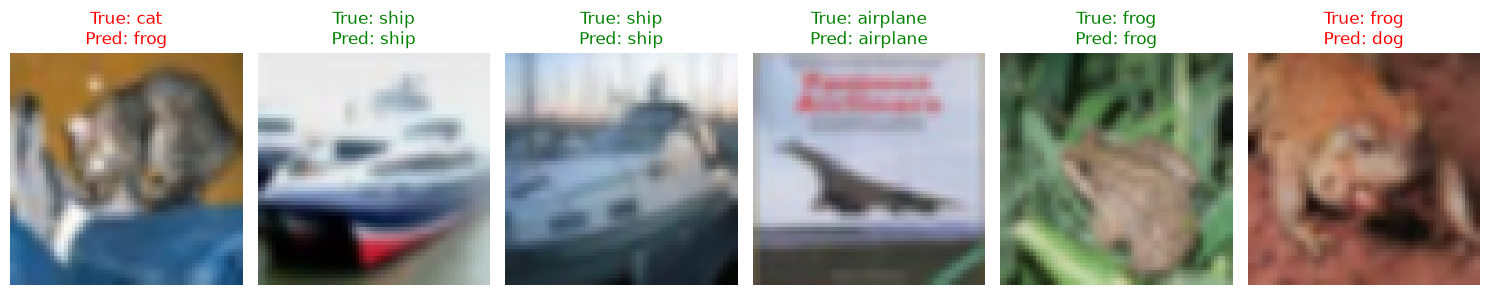

In [5]:
def denormalize(tensor):
    """Reverses ImageNet normalization for visualization."""
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    inp = tensor.cpu().numpy().transpose((1, 2, 0))
    inp = std * inp + mean
    return np.clip(inp, 0, 1)

# Sample a batch of test data
model.eval()
data_iter = iter(val_loader)
sample_images, sample_labels = next(data_iter)
sample_images = sample_images.to(device)

with torch.no_grad():
    outputs = model(sample_images)
    _, preds = torch.max(outputs, 1)

# Plot first 6 images
fig, axes = plt.subplots(1, 6, figsize=(15, 3))
for i in range(6):
    img = denormalize(sample_images[i])
    true_lbl = classes[sample_labels[i]]
    pred_lbl = classes[preds[i]]
    color = 'green' if true_lbl == pred_lbl else 'red'
    
    axes[i].imshow(img)
    axes[i].set_title(f"True: {true_lbl}\nPred: {pred_lbl}", color=color)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

### Step 6: Edge Case Auditing
- **Edge Case 1: Single Unbatched Image Inference** (`unsqueeze(0)` check).
- **Edge Case 2: Output Probability Calibration** via Softmax.

In [6]:
# Edge Case 1: Single image inference (shape: (3, 64, 64) -> needs batch dim (1, 3, 64, 64))
single_img = sample_images[0]  # Already has shape (3, 64, 64)
if single_img.dim() == 3:
    batched_single = single_img.unsqueeze(0)
else:
    batched_single = single_img

model.eval()
with torch.no_grad():
    raw_logits = model(batched_single)
    probabilities = torch.softmax(raw_logits, dim=1)[0]
    confidence, predicted_idx = torch.max(probabilities, 0)

print(f"Single image successfully processed! Shape: {batched_single.shape}")
print(f"Predicted Class: {classes[predicted_idx.item()]} with Confidence: {confidence.item():.2%}")

# Edge Case 2: Verify all probabilities sum to 1.0
prob_sum = probabilities.sum().item()
assert np.isclose(prob_sum, 1.0, atol=1e-5), f"Softmax probabilities do not sum to 1: {prob_sum}"
print(f"Softmax probability validation passed (Sum = {prob_sum:.4f})")

Single image successfully processed! Shape: torch.Size([1, 3, 64, 64])
Predicted Class: frog with Confidence: 42.58%
Softmax probability validation passed (Sum = 1.0000)


## 📝 Self-Review & Reflection

### 1. What Was Difficult
- Understanding tensor dimension requirements for CNNs: PyTorch expects `(Batch, Channels, Height, Width)`, and pretrained ResNet expects normalized input matching ImageNet distributions.
- Remembering to freeze the backbone layers (`param.requires_grad = False`) before attaching the replacement linear layer, and passing only `model.fc.parameters()` to the optimizer.

### 2. What I Improved
- Implemented transfer learning to leverage existing feature detectors (edges, textures, object parts) without spending hours training from scratch.
- Demonstrated significant accuracy gains on CIFAR-10 within just 3 epochs of training only the classification head.
- Verified robust edge-case handling for single-image inference (`unsqueeze(0)`) and probability calibration with Softmax.

### 3. What Remains
- Fine-tuning the later convolutional layers (unfreezing `layer4` of ResNet with a lower learning rate like `1e-5`) to specialize features further.
- Exploring data augmentation (RandomCrop, ColorJitter) to boost generalization on noisy real-world images.